# DNAscape mapping atlas (rmap)

This notebook introduces `rmap`, the DNAscape workflow for mapping between replication features through mathematical relationships derived under explicit mechanistic assumptions. Rather than simulating individual S phases, `rmap` uses deterministic transformations or fitted kinetic quantities to move between features such as origin firing activity, fork speed, replication timing, fork directionality, among others. It is therefore designed for well-defined scenarios in which the supplied data and the target quantity are expected to be linked by a specific modelling assumption.

The notebook is organised by **target feature**: first decide what you want to infer, then provide the data or kinetic quantities needed to infer it. In `rmap`, `source` contains the supplied replication data or model-derived quantities, while `assumptions` contains the settings that define the mapping route, such as `resolution_x`, geometry, target form and fitting controls.

**Data types.** We use replication timing (RT) as the main entry point and consider four targets: origin firing, fork speed, joint kinetic fields and replication timing itself. The arrays used by the model should be interpreted as kinetic representations of the underlying biology, rather than raw assay values. They should therefore be preprocessed according to the biological question being asked. See `1_datamanagement.ipynb` for details on data preparation and formatting.

**Space-time dependence.** When `rmap` is used to infer either `firing_rate` or `fork_speed`, `target_form` specifies the dependency structure of the inferred quantity: `constant` for a single fitted value, `space` for an $x$-dependent profile, `time` for a time-dependent profile and `spacetime` for a full $(x,t)$ field. If `target_form` is omitted, `rmap` defaults to `space` for both targets. 

**Fitting errors.** As the expected RT is uniquely determined from initiation rate and fork speed, the goodness of each fit and mapping is evaluated with the mean square error (MSE) between a reference timing profile and the predicted one.

## Table of contents

1. Setup
2. Target: Initiation rate $I(x,t)$
3. Target: Fork speed $v(x,t)$
4. Target: joint kinetic fields $I(x,t)$ and $v(x,t)$
5. Target: replication timing
6. Target: fork directionality
7. Target: replicated fraction $f(x,t)$
8. Target: fork density
9. Target: initiation-observation density
10. Target: fork termination
11. Target: replication-time distributions
12. Target: experimental observables

## 1. Setup

Autoreload keeps notebook runs aligned with source-code edits.

In [1]:
%reload_ext autoreload
%autoreload 2

from dnascape import *

### 1.1 Inspecting available mappings

`rmap.available()` lists the targets that can be requested.

In [2]:
rmap.available()

,target,description
0,firing_rate,Origin firing activity to infer or supply.
1,fork_speed,Fork progression speed to infer or supply.
2,kinetic_fields,Jointly fitted firing-rate and fork-speed fields.
3,replication_timing,Replication timing along genomic position.
4,fork_directionality,Net fork movement directionality along position.


For a specific target, `rmap.requirements()` shows the source data and assumptions needed to run the corresponding mappings.

In [3]:
rmap.requirements(target="fork_speed")

,
target,fork_speed
source (required data),"replication_timing, firing_rate"
assumptions,"target_form, resolution_x, resolution_t, time_grid, T0, perQ, neighbourhood_range, initial_fork_speed, speed_bounds, fit_step, maxiter, sim_number, fit_step_x, maxiter_x, fit_step_t, maxiter_t, sim_number_t, smoothw_t, fit_step_xt, sim_number_xt, spacetime_update, spacetime_order, kernel_xt_t, smoothw, refine_ratio_bounds, refine_edge_kb, refine_seed, refine_verbose"
target description,Fork progression speed to infer or supply.


The optional views below expose the expected data forms and the meaning of the assumptions.

In [4]:
rmap.requirements(target="fork_speed", show_data=True)

,role,quantity,form,target_form
0,source,replication_timing,array (space-dependent),-
1,source,firing_rate,scalar (constant in space and time),-
2,source,firing_rate,array (space-dependent),-
3,source,firing_rate,transposed array (time-dependent),-
4,source,firing_rate,matrix (space-time dependent),-
5,target,fork_speed,scalar (constant in space and time),constant
6,target,fork_speed,array (space-dependent),space
7,target,fork_speed,transposed array (time-dependent),time
8,target,fork_speed,matrix (space-time dependent),spacetime


In [5]:
rmap.requirements(target="firing_rate", explain_assumptions=True)

,assumption,default,description
0,target_form,space,"Requested output form: scalar (constant in space and time), array (space-dependent), transposed array (time-dependent), or matrix (space-time dependent)."
1,resolution_x,1.0,"Spatial resolution along the genome, in kb."
2,resolution_t,1.0,"Temporal resolution, in minutes."
3,time_grid,None,Explicit time axis to use for time-dependent fields.
4,T0,None,Reference start time used when converting timing values to a relative time axis.
5,perQ,False,Whether the genome is treated as periodic/circular.
6,neighbourhood_range,2000,"Spatial range, in kb, used by deterministic neighbourhood mappings."
7,rate_bounds,None,Allowed lower and upper bounds for scalar firing-rate fitting.
8,fit_step,0.6,"Global multiplicative update size. For x,t targets it sets fit_step_x and fit_step_t unless those are supplied explicitly."
9,maxiter,10,"Global iteration count. For x,t targets it overrides maxiter_x and maxiter_t, setting both to the same value."


### 1.2 Example data

We use the hESC chromosome 1 replication-timing profile as an example for `rmap` usage. The selected profile is a one-dimensional `T(x)` array, and `positions_kb` gives the matching genomic coordinates. Here, we consider data at a 1-kilobase resolution.

In [6]:
chr_number = 1
interval_kb = (0, 60_000)

replication_timing_full = loadcsv(
    "example",
    example="replication_timing_hESC",
    chr_number=chr_number,
)

replication_timing, positions_kb = select_profile_region(
    replication_timing_full,
    interval_kb=interval_kb,
)

n_positions = replication_timing.size

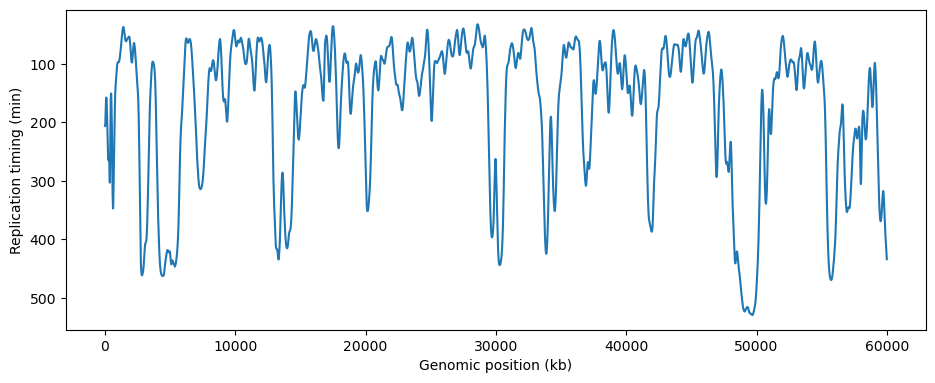

In [7]:
plotf(
    replication_timing,
    x_array=positions_kb,
    invyQ=True,
    xtitle="Genomic position (kb)",
    ytitle="Replication timing (min)",
)

## 2. Target: Initiation rate $I(x,t)$

Origin firing rate can be mapped from replication timing and fork speed under explicit space-time assumptions. We assume replication timing is supplied as a position-specific array, and `rmap` detects whether fork speed is constant or varies over space and/or time from the shape of the input. In the examples below, the optimisation settings are handled internally by DNAscape defaults but can be tweaked for optimisation (see Section 5. Optimisations).

### 2.1 Uniform initiation $I=I_0$

If we assume constant fork speed (a scalar input $v=v_0$) and want to infer a constant initiation rate (a scalar output $I=I_0$), we may set `target_form` to `"constant"` in `rmap` as follows

In [8]:
fork_speed = 1.4 # in kb/min

firing_rate_constant = rmap(
    source={
        "replication_timing": replication_timing,
        "fork_speed": fork_speed,
    },
    target="firing_rate",
    assumptions={
        "target_form": "constant"
    }
)

print(f"Optimal uniform firing rate: {firing_rate_constant}")

Optimal uniform firing rate: 3.974187322944415e-058300e+04


`rmap` returns the optimal uniform initiation rate (a scalar $I_0$), that best matches the RT curve. We may then use this scalar and the constant fork speed to simulate the replication timing profile and have a way to compare with the timing data source. Like `rmap`, `rsim` automatically detects the constant fork speed assumption if given as a scalar. In the particular cases where the initiation rate is assumed independent of space, the simulation region should be given as an assumption, through `interval_kb`. See `3_simulation.ipynb` for the full `rsim` usage details.

In [9]:
replication_timing_sim = rsim(
    source={
        "firing_rate": firing_rate_constant,
        "fork_speed": fork_speed,
    },
    assumptions={
        "sim_number": 100,
        "interval_kb": interval_kb,
    },
)["replication_timing"]

Which can be compared with the RT data

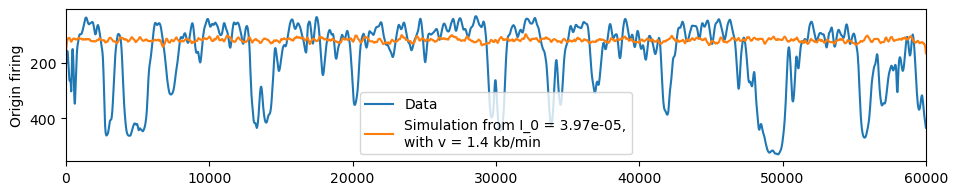

In [10]:
mplotf(
    [
        [replication_timing, replication_timing_sim],
    ],
    mlabels=[
        ["Data", f"Simulation from I_0 = {firing_rate_constant:.2e},\nwith v = {fork_speed} kb/min"],
    ],
    mx_array=positions_kb,
    minvyQ=[True],
    mxtitle=["", "", "Genomic position (kb)"],
    mytitle=["Origin firing", "RT (min)"],
    figsize=(10, 1.9),
)

Unsurprisingly, although DNAscape tries to find the optimal $I_0$, the uniform assumption is not strong enough to to infer timing.

### 2.2 Space-dependent initiation $I(x)$

Instead, if may assume a space-dependent initiation rate, $I(x)$, which can be obtained by setting `target_form` to `"space"`

In [11]:
fork_speed = 1.4

firing_rate_space = rmap(
    source={
        "replication_timing": replication_timing,
        "fork_speed": fork_speed,
    },
    target="firing_rate",
    assumptions={
        "target_form": "space",
    }
)

Now, `rmap` returns an array where each entry corresponds to a firing rate at each kilobase. Again, we may use this array and the constant fork speed to simulate the replication timing profile.

In [12]:
replication_timing_sim = rsim(
    source={
        "firing_rate": firing_rate_space,
        "fork_speed": fork_speed,
    },
    assumptions={
        "sim_number": 100,
    },
)["replication_timing"]

We may then plot the fitted firing rate profile, with its corresponding timing profile and data reference.

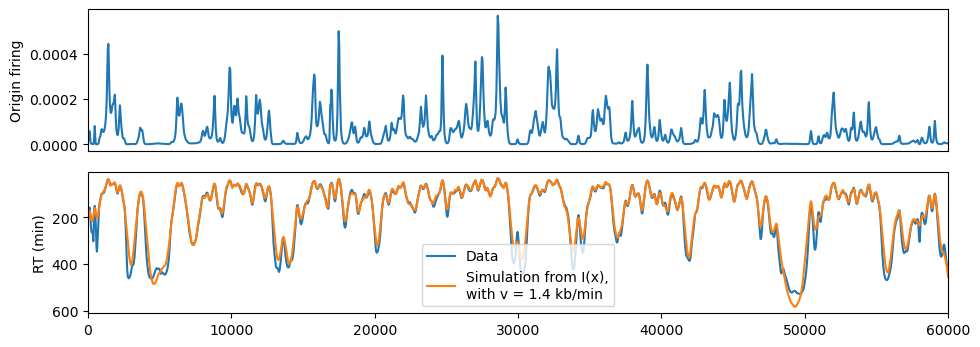

In [13]:
mplotf(
    [
        firing_rate_space,
        [replication_timing, replication_timing_sim],
    ],
    mlabels=[
        None,
        ["Data", f"Simulation from I(x),\nwith v = {fork_speed} kb/min"],
    ],
    mx_array=positions_kb,
    minvyQ=[False, True],
    mxtitle=["", "", "Genomic position (kb)"],
    mytitle=["Origin firing", "RT (min)"],
    figsize=(10, 1.9),
)

### 2.3 Time-dependent initiation $I(t)$

Alternatively, one might assume a model where initiation rate is a time-only feature, with origin firing rates changing only across S phase. In this case, one may `target_form` to `"time"`, while fixing a time discretisation with `resolution_t` (in minutes).

In [14]:
firing_rate_time = rmap(
    source={
        "replication_timing": replication_timing,
        "fork_speed": fork_speed,
    },
    target="firing_rate",
    assumptions={
        "target_form": "time",
        "resolution_t": 5,
    }
)

[10/10]  Elapsed: 00:00:21  ETA: 00:00:00  MSE: 5.4191e+02
Refining time-dependent firing rate...


In [15]:
replication_timing_sim_time = rsim(
    source={
        "firing_rate": firing_rate_time,
        "fork_speed": fork_speed,
    },
    assumptions={
        "sim_number": 100,
        "interval_kb": interval_kb,
        "resolution_t": 5,
    },
)["replication_timing"]

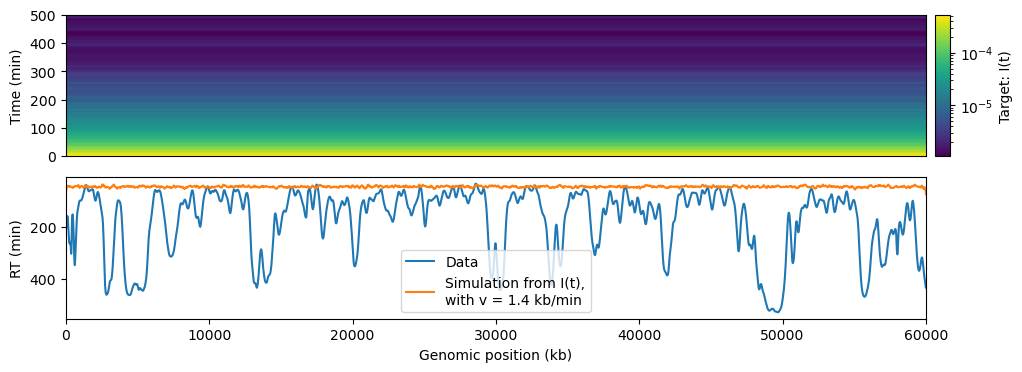

In [16]:
mplotf(
    [
        firing_rate_time,
        [replication_timing, replication_timing_sim_time],
    ],
    mlabels=[
        ["Target: I(t)"],
        ["Data", f"Simulation from I(t),\nwith v = {fork_speed} kb/min"],
    ],
    mx_array=positions_kb,
    mresolution_t=[5, 1],
    minvyQ=[False, True],
    mlogzQ=[True, False],
    mxtitle=["", "Genomic position (kb)"],
    mytitle=["Time (min)", "RT (min)"],
    figsize=(10, 1.9),
)

Unlike in the previous section, time-dependent initiation rate and constant fork speed are equally insufficient to match replication timing profiles.

### 2.4 Spacetime-dependent initiation $I(x,t)$

A full space-time initiation field keeps both genomic position and S-phase time explicit. This is the most flexible initiation-only target available, but it may be prone to overfitting and should therefore be used with care. In this case, we set `target_form` to `"spacetime"`.

In [17]:
firing_rate_spacetime = rmap(
    source={
        "replication_timing": replication_timing,
        "fork_speed": fork_speed,
    },
    target="firing_rate",
    assumptions={
        "target_form": "spacetime",
        "resolution_t": 5,
        "maxiter": 10
    }
)

[10/10]  Elapsed: 00:00:24  ETA: 00:00:00  MSE: 5.4191e+02
Refining factorized time component of firing rate...


In [18]:
replication_timing_sim_spacetime = rsim(
    source={
        "firing_rate": firing_rate_spacetime,
        "fork_speed": fork_speed,
    },
    assumptions={
        "sim_number": 100,
        "resolution_t": 5,
    },
)["replication_timing"]

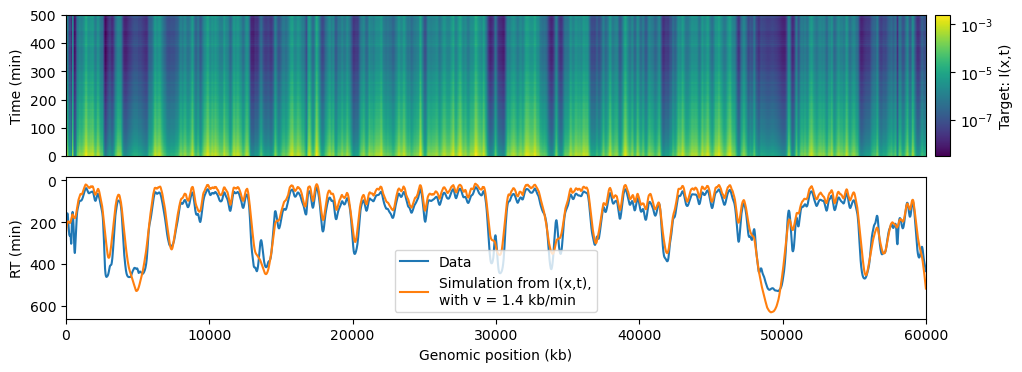

In [19]:
mplotf(
    [
        firing_rate_spacetime,
        [replication_timing, replication_timing_sim_spacetime],
    ],
    mlabels=[
        ["Target: I(x,t)"],
        ["Data", f"Simulation from I(x,t),\nwith v = {fork_speed} kb/min"],
    ],
    mx_array=positions_kb,
    mresolution_t=[5, 1],
    minvyQ=[False, True],
    mlogzQ=[True, False],
    mxtitle=["", "Genomic position (kb)"],
    mytitle=["Time (min)", "RT (min)"],
    figsize=(10, 1.9),
)

## 3. Target: Fork speed $v(x,t)$

Fork speed can be mapped from replication timing when origin firing is supplied as the second kinetic input. Here we keep timing fixed as the data source and vary the firing-rate form: a uniform rate $I_0$, a spatial profile $I(x)$, or the space-time field $I(x,t)$ estimated above. As in Section 1, `target_form` defines the dependency structure of the inferred fork speed, while the fitting controls are left to the internal defaults.

### 3.1 Uniform initiation $I_0$ to spatial fork speed $v(x)$

With a uniform initiation baseline, `rmap` asks how much regional fork-speed variation is needed to explain the timing profile.

In [20]:
fork_speed_space_from_I0 = rmap(
    source={
        "replication_timing": replication_timing,
        "firing_rate": firing_rate_constant,
    },
    target="fork_speed",
    assumptions={
        "target_form": "space",
    }
)

In [21]:
replication_timing_sim_speed_I0_space = rsim(
    source={
        "firing_rate": firing_rate_constant,
        "fork_speed": fork_speed_space_from_I0,
    },
    assumptions={
        "sim_number": 100,
    },
)["replication_timing"]

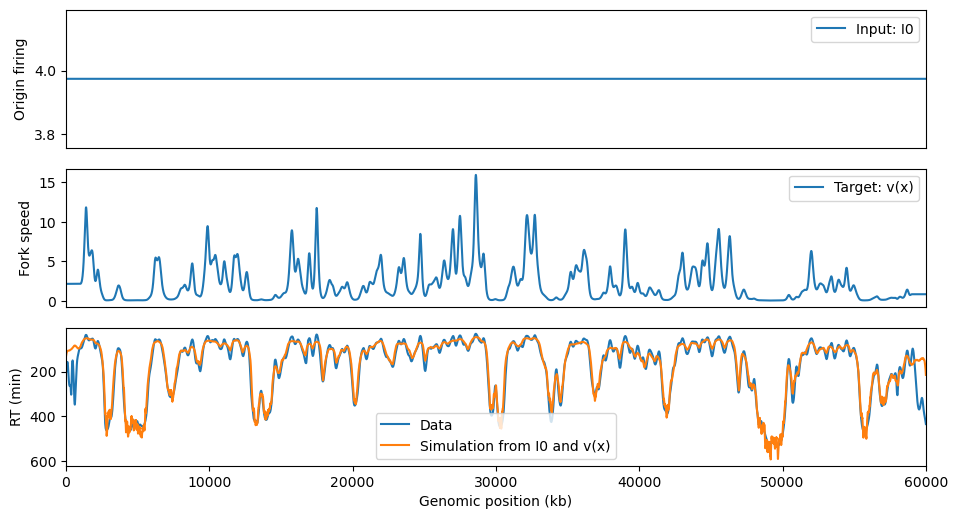

In [22]:
mplotf(
    [
        np.full(n_positions, firing_rate_constant),
        fork_speed_space_from_I0,
        [replication_timing, replication_timing_sim_speed_I0_space],
    ],
    mlabels=[
        ["Input: I0"],
        ["Target: v(x)"],
        ["Data", "Simulation from I0 and v(x)"],
    ],
    mx_array=positions_kb,
    minvyQ=[False, False, True],
    mxtitle=["", "", "Genomic position (kb)"],
    mytitle=["Origin firing", "Fork speed", "RT (min)"],
    figsize=(10, 1.9),
)

### 3.2 Spatial initiation $I(x)$ to spatial fork speed $v(x)$

When initiation is already spatially resolved, the fitted speed profile captures the remaining positional structure needed to match timing.

In [23]:
fork_speed_space = rmap(
    source={
        "replication_timing": replication_timing,
        "firing_rate": firing_rate_space,
    },
    target="fork_speed",
    assumptions={
        "target_form": "space",
    }
)

In [24]:
replication_timing_sim_speed_Ix_space = rsim(
    source={
        "firing_rate": firing_rate_space,
        "fork_speed": fork_speed_space,
    },
    assumptions={
        "sim_number": 100,
    },
)["replication_timing"]

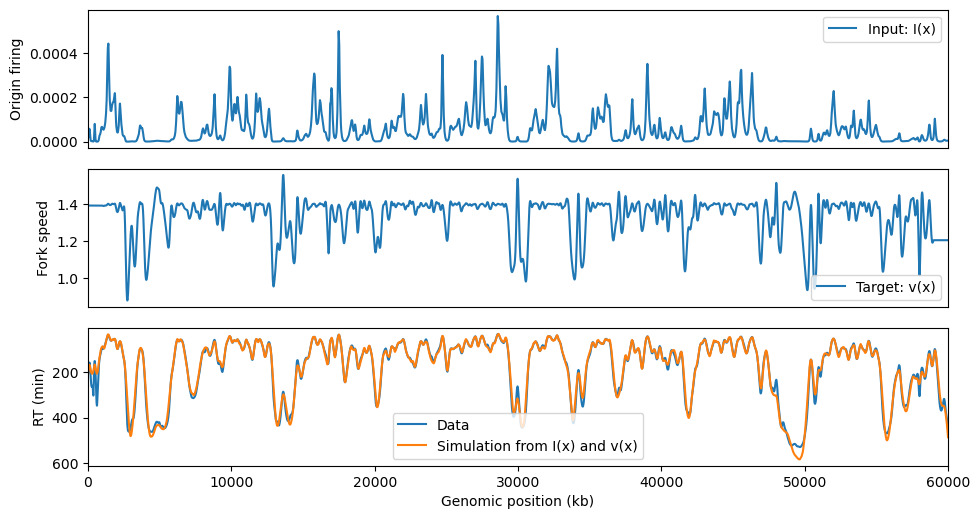

In [25]:
mplotf(
    [
        firing_rate_space,
        fork_speed_space,
        [replication_timing, replication_timing_sim_speed_Ix_space],
    ],
    mlabels=[
        ["Input: I(x)"],
        ["Target: v(x)"],
        ["Data", "Simulation from I(x) and v(x)"],
    ],
    mx_array=positions_kb,
    minvyQ=[False, False, True],
    mxtitle=["", "", "Genomic position (kb)"],
    mytitle=["Origin firing", "Fork speed", "RT (min)"],
    figsize=(10, 1.9),
)

### 3.3 Spatial initiation $I(x)$ to time-dependent fork speed $v(t)$

This route compresses the spatial speed fit onto the S-phase time coordinate and refines the temporal profile internally.

In [26]:
fork_speed_time_from_Ix = rmap(
    source={
        "replication_timing": replication_timing,
        "firing_rate": firing_rate_space,
    },
    target="fork_speed",
    assumptions={
        "target_form": "time",
        "resolution_t": 5,
    }
)

[40/40]  Elapsed: 00:01:24  ETA: 00:00:00  MSE: 7.8596e+00
Refining time-dependent fork speed...


In [27]:
replication_timing_sim_speed_Ix_time = rsim(
    source={
        "firing_rate": firing_rate_space,
        "fork_speed": fork_speed_time_from_Ix,
    },
    assumptions={
        "sim_number": 100,
        "resolution_t": 5,
    },
)["replication_timing"]

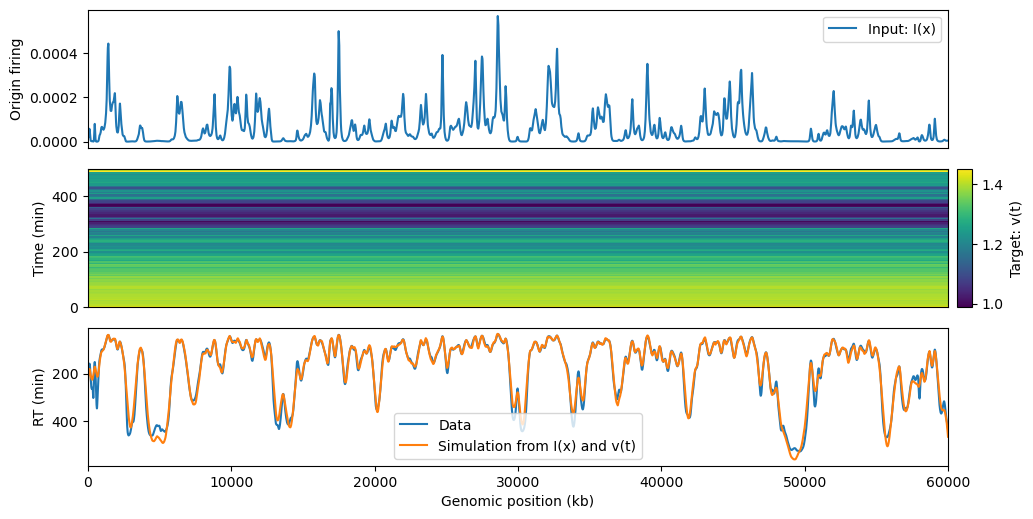

In [28]:
mplotf(
    [
        firing_rate_space,
        fork_speed_time_from_Ix,
        [replication_timing, replication_timing_sim_speed_Ix_time],
    ],
    mlabels=[
        ["Input: I(x)"],
        ["Target: v(t)"],
        ["Data", "Simulation from I(x) and v(t)"],
    ],
    mx_array=positions_kb,
    mresolution_t=[1, 5, 1],
    minvyQ=[False, False, True],
    mxtitle=["", "", "Genomic position (kb)"],
    mytitle=["Origin firing", "Time (min)", "RT (min)"],
    figsize=(10, 1.9),
)

### 3.4 Space-time initiation $I(x,t)$ to space-time fork speed $v(x,t)$

The most general one-target speed fit keeps both axes explicit, returning a space-time fork-speed field from timing and $I(x,t)$. This should be interpreted carefully: replication timing is a one-dimensional profile, while $v(x,t)$ has many more degrees of freedom, so the fitted field is generally not uniquely determined by timing alone. Unless constrained by independent fork-speed data or strong biological assumptions, $v(x,t)$ is best read as an effective propagation field that can absorb initiation assumptions, passive replication and model mismatch, rather than as a direct molecular fork-velocity map.

In [29]:
fork_speed_spacetime_from_Ixt = rmap(
    source={
        "replication_timing": replication_timing,
        "firing_rate": firing_rate_spacetime,
    },
    target="fork_speed",
    assumptions={
        "target_form": "spacetime",
        "resolution_t": 5,
    }
)

[40/40]  Elapsed: 00:01:35  ETA: 00:00:00  MSE: 3.0097e+01
Refining factorized time component of fork speed...


In [30]:
replication_timing_sim_speed_Ixt_spacetime = rsim(
    source={
        "firing_rate": firing_rate_spacetime,
        "fork_speed": fork_speed_spacetime_from_Ixt,
    },
    assumptions={
        "sim_number": 100,
        "resolution_t": 5,
    },
)["replication_timing"]

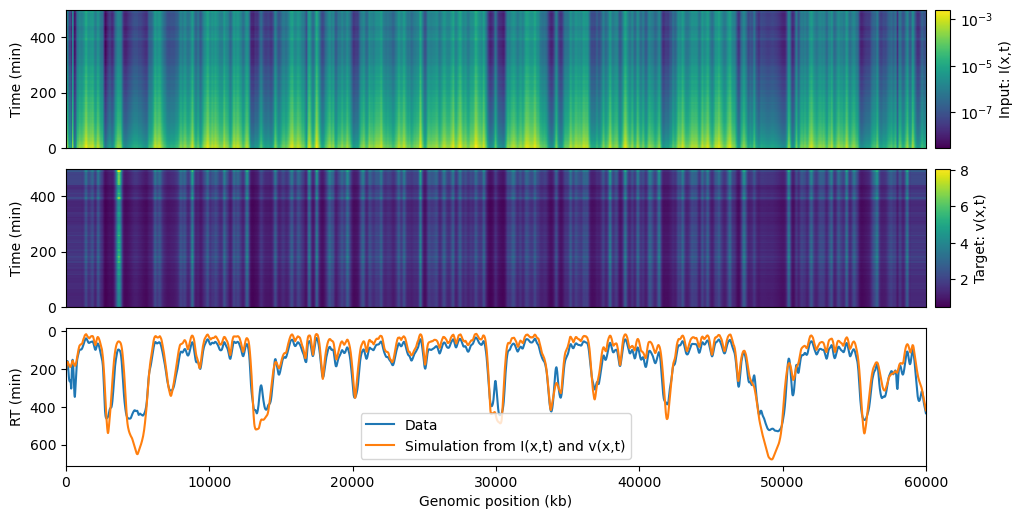

In [31]:
mplotf(
    [
        firing_rate_spacetime,
        fork_speed_spacetime_from_Ixt,
        [replication_timing, replication_timing_sim_speed_Ixt_spacetime],
    ],
    mlabels=[
        ["Input: I(x,t)"],
        ["Target: v(x,t)"],
        ["Data", "Simulation from I(x,t) and v(x,t)"],
    ],
    mx_array=positions_kb,
    mresolution_t=[5, 5, 1],
    minvyQ=[False, False, True],
    mlogzQ=[True, False, False],
    mxtitle=["", "", "Genomic position (kb)"],
    mytitle=["Time (min)", "Time (min)", "RT (min)"],
    figsize=(10, 1.9),
)

## 4. Target: joint kinetic fields $I(x,t)$ and $v(x,t)$

This route uses replication timing alone to fit initiation and fork-speed fields simultaneously. It is different from first estimating $I(x,t)$ and then fitting $v(x,t)$: both fields are updated together from the same timing residual, giving one compatible kinetic decomposition of the data. The solution is not unique, and the flexibility of two full space-time fields can naturally overfit timing; the point here is to showcase the most expressive mapping option when that flexibility is useful.

In [ ]:
joint_kinetics = rmap(
    source={
        "replication_timing": replication_timing,
    },
    target="kinetic_fields",
    assumptions={
        "target_form": "spacetime",
        "resolution_t": 5,
        "maxiter": 20,
    },
)

firing_rate_joint = joint_kinetics["firing_rate"]
fork_speed_joint = joint_kinetics["fork_speed"]
joint_kinetics["fit_history"]

KeyboardInterrupt: 

The fitted fields can be sent directly to `rsim`. The timing row below compares the original RT data with a stochastic simulation driven by the jointly fitted kinetics.

In [ ]:
replication_timing_sim_joint = rsim(
    source={
        "firing_rate": firing_rate_joint,
        "fork_speed": fork_speed_joint,
    },
    assumptions={
        "sim_number": 100,
        "resolution_t": 5,
    },
)["replication_timing"]

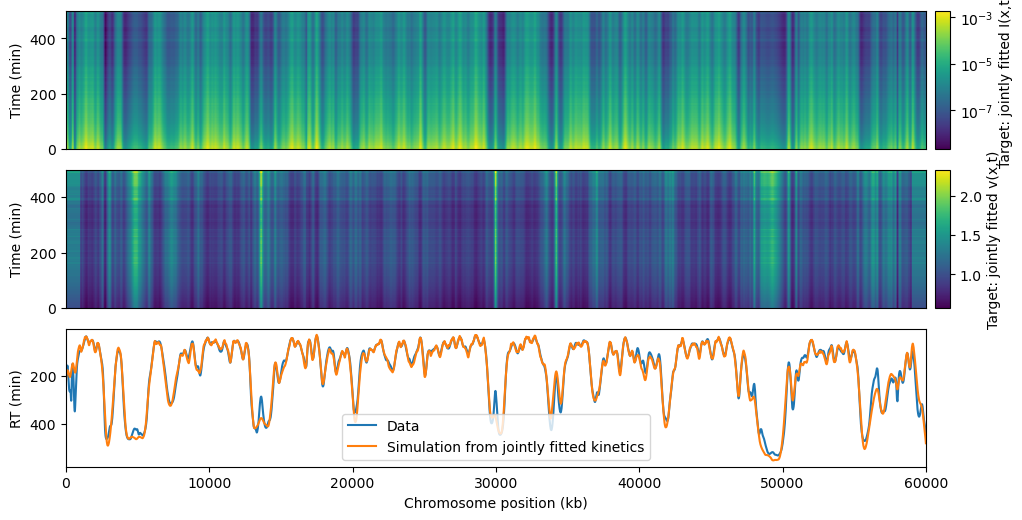

In [ ]:
mplotf(
    [
        firing_rate_joint,
        fork_speed_joint,
        [replication_timing, replication_timing_sim_joint],
    ],
    mlabels=[
        ["Target: jointly fitted I(x,t)"],
        ["Target: jointly fitted v(x,t)"],
        ["Data", "Simulation from jointly fitted kinetics"],
    ],
    mx_array=positions_kb,
    mresolution_t=[5, 5, 1],
    minvyQ=[False, False, True],
    mlogzQ=[True, False, False],
    mxtitle=["", "", "Genomic position (kb)"],
    mytitle=["Time (min)", "Time (min)", "RT (min)"],
    figsize=(10, 1.9),
)

## 5. Target: replication timing

Replication timing can be mapped forward from supplied kinetic fields. Here we keep the section compact and map the fitted spatial initiation profile and constant fork speed back to timing.

### 5.1 Spatial initiation $I(x)$ and constant fork speed $v_0$

This direct forward map uses `firing_rate_space`, fitted above from the timing data, together with the constant `fork_speed`. The target is the timing profile implied by those two kinetic inputs.

In [32]:
spatial_timing_fit = rmap(
    source={
        "firing_rate": firing_rate_space,
        "fork_speed": fork_speed,
    },
    target="replication_timing",
    return_info=True,
)

timing_from_firing = spatial_timing_fit["values"]
replication_timing_sim_from_firing = rsim(
    source={
        "firing_rate": firing_rate_space,
        "fork_speed": fork_speed,
    },
    assumptions={
        "sim_number": 100,
        "verbose": False,
    },
)["replication_timing"]

print(spatial_timing_fit["method"], timing_from_firing.shape)

firing_and_speed_to_timing_deterministic (60000,)


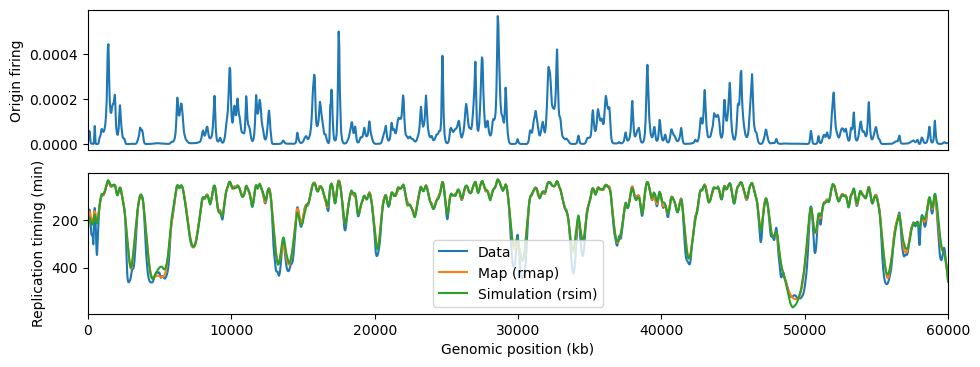

In [33]:
mplotf(
    [
        firing_rate_space,
        [replication_timing, timing_from_firing, replication_timing_sim_from_firing],
    ],
    mlabels=[
        None,
        ["Data", "Map (rmap)", "Simulation (rsim)"],
    ],
    mx_array=[positions_kb, positions_kb, positions_kb],
    minvyQ=[False, True],
    mxtitle="Genomic position (kb)",
    mytitle=["Origin firing", "Replication timing (min)"],
    figsize=(10, 1.9),
    hspace=0.16,
)

## 6. Target: fork directionality

Fork directionality summarizes the local bias in fork movement along the chromosome. In `rmap`, it can be obtained directly from replication timing and fork speed. We first use a constant fork-speed assumption, then repeat the same map with the spatial fork-speed profile fitted above.

### 6.1 Timing and constant fork speed $v_0$

With constant fork speed, directionality follows from the timing gradient alone under the chosen speed scale.

In [34]:
directionality_v0_fit = rmap(
    source={
        "replication_timing": replication_timing,
        "fork_speed": fork_speed,
    },
    target="fork_directionality",
    assumptions={
        "T0": replication_timing[0],
    },
    return_info=True,
)

fork_directionality_v0 = directionality_v0_fit["values"]

print(directionality_v0_fit["method"], fork_directionality_v0.shape)

timing_and_speed_to_directionality (60000,)


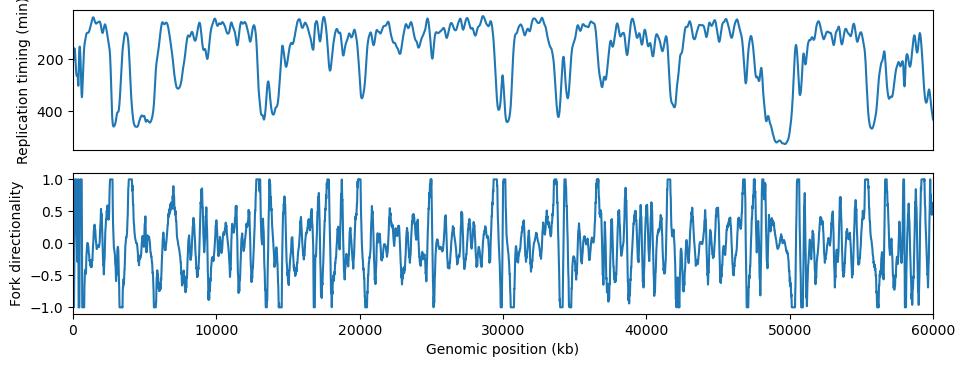

In [35]:
mplotf(
    [
        replication_timing,
        fork_directionality_v0,
    ],
    mlabels=[
        None,
        None,
    ],
    mx_array=positions_kb,
    minvyQ=[True, False],
    mxtitle=["", "Genomic position (kb)"],
    mytitle=["Replication timing (min)", "Fork directionality"],
    figsize=(10, 1.9),
    hspace=0.16,
)

### 6.2 Timing and spatial fork speed $v(x)$

The same mapping can use an x-dependent fork-speed profile. Here `fork_speed_space` keeps local speed variation explicit while the timing profile supplies the gradient.

In [36]:
directionality_vx_fit = rmap(
    source={
        "replication_timing": replication_timing,
        "fork_speed": fork_speed_space,
    },
    target="fork_directionality",
    assumptions={
        "T0": replication_timing[0],
    },
    return_info=True,
)

fork_directionality_vx = directionality_vx_fit["values"]

print(directionality_vx_fit["method"], fork_directionality_vx.shape)

timing_and_spatial_speed_to_directionality (60000,)


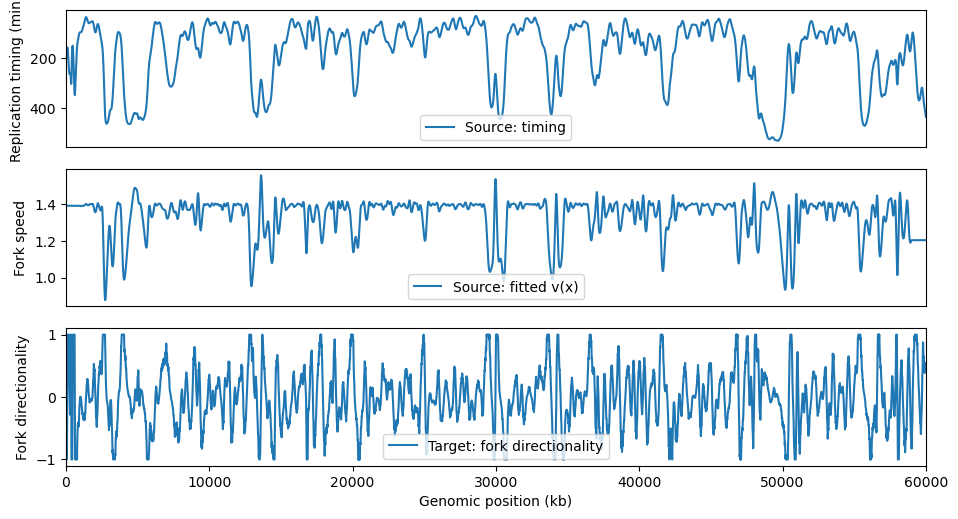

In [37]:
mplotf(
    [
        replication_timing,
        fork_speed_space,
        fork_directionality_vx,
    ],
    mlabels=[
        ["Source: timing"],
        ["Source: fitted v(x)"],
        ["Target: fork directionality"],
    ],
    mx_array=positions_kb,
    minvyQ=[True, False, False],
    mxtitle=["", "", "Genomic position (kb)"],
    mytitle=["Replication timing (min)", "Fork speed", "Fork directionality"],
    figsize=(10, 1.9),
    hspace=0.16,
)

**Note on interpretation.** The spatial speed used here is a fitted effective propagation profile, not necessarily an independently measured molecular fork velocity. It can absorb initiation assumptions, timing noise and model mismatch. The simulation below should therefore be read as a consistency check: `rsim` uses the fitted `I(x)` and effective `v(x)` to generate fork directionality, which can then be compared with the `rmap` directionality implied by timing and the same `v(x)`.

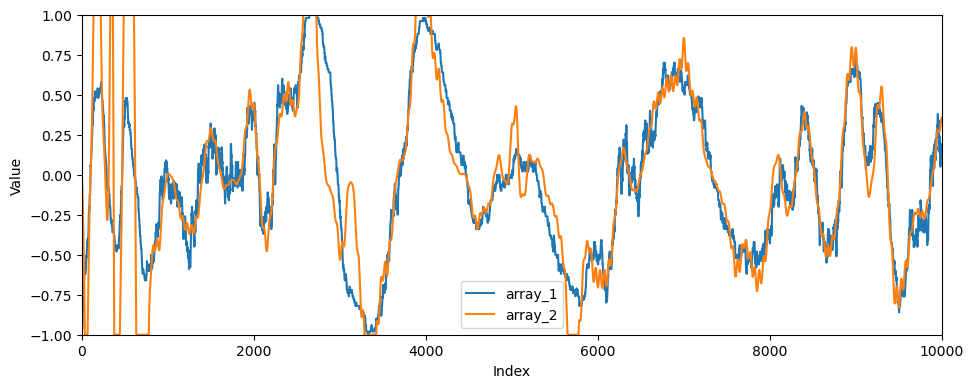

In [38]:
directionality_vx_fit_test = rsim(
    source={
        "firing_rate": firing_rate_space,
        "fork_speed": fork_speed_space,
    },
    assumptions={
        "sim_number": 100,
    },
)["fork_directionality"]

plotf(directionality_vx_fit_test,fork_directionality_vx,ylims=(-1,1),xlims=(0,10000))

## 7. Target: replicated fraction $f(x,t)$

The most general way to represent the replication programme is through the replicated fraction function, $f(x,t)$. For each genomic position $x$ and time $t$, $f(x,t)$ denotes the fraction of cells in which that locus has already been replicated by time $t$. Equivalently, $1-f(x,t)$ is the probability that the locus remains unreplicated.

Given an initiation rate $I(x,t)$ and fork-speed field $v(x,t)$, $f(x,t)$ is obtained as a forward map from kinetic inputs to the replication state of the genome. In the KJMA formulation, a locus remains unreplicated at time $t$ only if no origin has fired within the past light cone of $(x,t)$, namely within the set of initiation events whose forks could have reached $x$ by time $t$. This gives

$$
f(x,t)=1-\exp\left[-\iint_{V_X[v]} I(\xi,\tau)\,d\xi\,d\tau\right].
$$

Here, $V_X[v]$ denotes the past light cone of position $x$ at time $t$, with boundaries determined by the fork-speed field $v$. Intuitively, the integral measures the cumulative initiation hazard over all possible events that could have replicated the locus by that time.

This is a useful high-level representation of the full replication process, but it is not always the most direct object to compare with experimental data. Many assays measure lower-dimensional summaries, such as replication timing, fork directionality, copied-fraction profiles, origin efficiency or fork-density dynamics, rather than the full space-time field $f(x,t)$. Nevertheless, DNAscape can evaluate this forward map directly from $I$ and $v$, making it possible to inspect the full replication programme before reducing it to experimentally comparable features.

In DNAscape, `rmap(..., target="replicated_fraction_xt")` evaluates the light-cone integral and returns a time-by-position matrix. The heatmaps below illustrate how different kinetic assumptions change the full replication programme, not only its timing summary.

For a clearer illustration, we begin by setting a time-axis resolution and further subsetting the focal genomic region.

In [211]:
fraction_resolution_t = 5
fraction_time_grid = np.arange(0, 800, fraction_resolution_t)

subset_region_kb = range(0, 10_000)
positions_kb_subset = positions_kb[subset_region_kb]
firing_rate_space_subset = firing_rate_space[subset_region_kb]
fork_speed_space_subset = fork_speed_space[subset_region_kb]

### 7.1 Spatial initiation $I(x)$ and fork speed $v(x)$

This first forward map uses the spatial initiation profile fitted above and keeps fork speed constant.

In [212]:
replicated_fraction_xt = rmap(
    source={
        "firing_rate": firing_rate_space_subset,
        "fork_speed": fork_speed_space_subset,
    },
    target="replicated_fraction_xt",
    assumptions={
        "time_grid": fraction_time_grid,
        "resolution_t": fraction_resolution_t,
    },
)

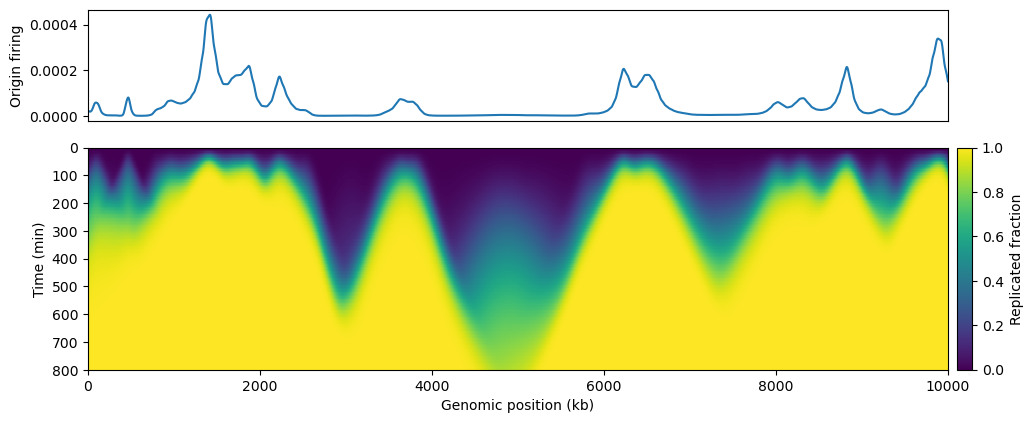

In [214]:
mplotf(
    [
        firing_rate_space_subset,
        replicated_fraction_xt,
    ],
    mlabels=[
        None,
        ["Replicated fraction"],
    ],
    mx_array=positions_kb_subset,
    mtime_array=[None, fraction_time_grid],
    mxtitle="Genomic position (kb)",
    mytitle=["Origin firing", "Time (min)"],
    mzlims=[None, (0, 1)],
    minvyQ=[False, True],
    mheight_ratios=[1, 2],
    figsize=(10, 2.25),
    hspace=0.16,
)

### 7.2 Spatial initiation $I(x)$ and spatial fork speed $v(x)$

Here both kinetic inputs vary along the chromosome, so the heatmap reflects how initiation and effective propagation structure combine over time. To illustrate this effect clearly, we define a smooth fork-speed profile with a baseline of 1.4 kb/min that decreases towards 0.01 kb/min across the 6-8 Mb region.

In [217]:
fast_fork_speed = 1.4
slow_fork_speed = 0.01

slow_region = 0.5 * (
    np.tanh((positions_kb_subset - 4_000) / 300)
    - np.tanh((positions_kb_subset - 8_000) / 300)
)
fork_speed_space_subset_example = fast_fork_speed - (fast_fork_speed - slow_fork_speed) * slow_region

In [218]:
replicated_fraction_xt_example = rmap(
    source={
        "firing_rate": firing_rate_space_subset,
        "fork_speed": fork_speed_space_subset_example,
    },
    target="replicated_fraction_xt",
    assumptions={
        "time_grid": fraction_time_grid,
        "resolution_t": fraction_resolution_t,
    },
)

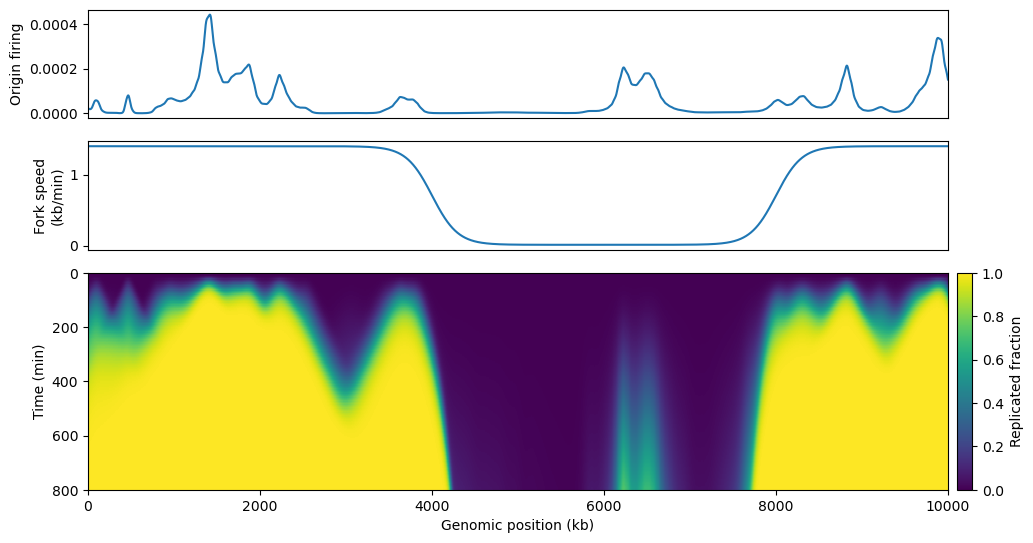

In [219]:
mplotf(
    [
        firing_rate_space_subset,
        fork_speed_space_subset_example,
        replicated_fraction_xt_example,
    ],
    mlabels=[
        None, None,
        ["Replicated fraction"],
    ],
    mx_array=positions_kb_subset,
    mtime_array=[None, None, fraction_time_grid],
    mxtitle="Genomic position (kb)",
    mytitle=["Origin firing", "Fork speed\n(kb/min)", "Time (min)"],
    mzlims=[None, None, (0, 1)],
    minvyQ=[False, False, True],
    mheight_ratios=[1, 1, 2],
    figsize=(10, 2.0),
    hspace=0.16,
)

Interesting results can be obtained by comparing replicated-fraction profiles across conditions,

$$
\Delta f(x,t)=|f_A(x,t)-f_B(x,t)|.
$$

This quantity highlights the genomic regions and time windows where two replication programmes differ most strongly. For example, when comparing cell types or perturbations with different fork-speed profiles, $\Delta f(x,t)$ can reveal where altered fork progression produces transient delays or advances in genome replication.

Although $f(x,t)$ is a high-level model quantity and is not always directly measurable, differences in $f$ can expose effects that are compressed or hidden in summary features such as mean replication timing. This makes $\Delta f(x,t)$ a useful way to visualise replication stress at the level of the full space-time replication programme, before reducing the model output to experimentally comparable quantities.

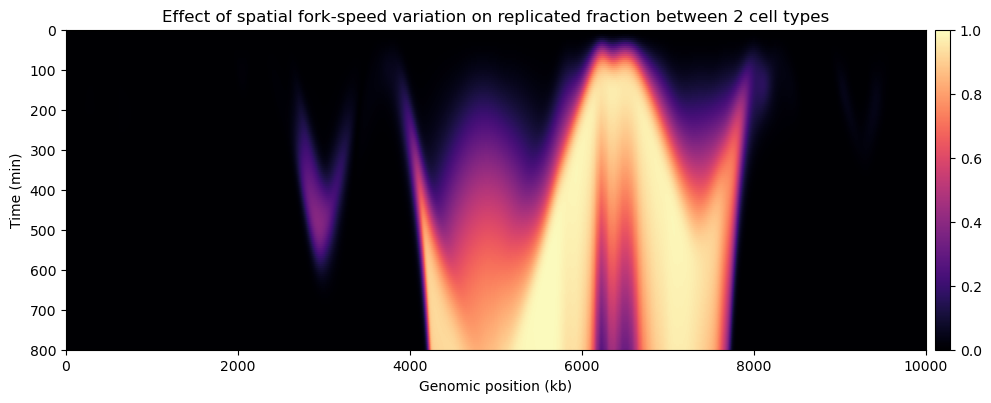

In [231]:
plotf(
    abs(replicated_fraction_xt - replicated_fraction_xt_example),
    x_array=positions_kb_subset,
    time_array=fraction_time_grid,
    xtitle="Genomic position (kb)",
    ytitle="Time (min)",
    title=r"Effect of spatial fork-speed variation on replicated fraction between 2 cell types",
    zlims=(0, 1),
    invyQ=True,
    cmap="magma",
)

## 8. Target: fork density

Fork density describes the expected number of active replication forks per unit genomic length at each position and time. The two directional fields, $\rho_+(x,t)$ and $\rho_-(x,t)$, represent right- and left-moving forks, respectively. Together with the replicated fraction, they form the fundamental mean-field description generated from initiation $I(x,t)$ and directional fork speeds $v_+(x,t)$ and $v_-(x,t)$.

Their coupled evolution is described by

$$
\frac{\partial f}{\partial t}=v_+\rho_+ + v_-\rho_-,
$$

$$
\frac{\partial \rho_\pm}{\partial t}
\pm \frac{\partial (v_\pm\rho_\pm)}{\partial x}
=I(1-f)-\frac{(v_++v_-)\rho_+\rho_-}{1-f}.
$$

The source term creates one fork in each direction when an origin fires in unreplicated DNA. The sink term removes opposing forks when they coalesce. Solving these equations provides $f$, $\rho_+$ and $\rho_-$ in one calculation and establishes the common kinetic foundation for the mappings in the following sections.

### 8.1 Directional fork densities $\rho_+(x,t)$ and $\rho_-(x,t)$

The first mapping retains fork orientation explicitly. We use the spatial initiation profile $I(x)$ fitted in section 2.2 and the spatial fork-speed profile $v(x)$ fitted in section 3.2. For this example, fork progression is symmetric, $v_+(x)=v_-(x)=v(x)$, so differences between $\rho_+(x,t)$ and $\rho_-(x,t)$ arise from initiation structure, propagation and genomic boundaries rather than direction-specific speeds.

The two directional densities are calculated together from the same mean-field integration and displayed on a shared colour scale. This makes their magnitudes directly comparable across position and time.

In [232]:
fork_densities_xt = rmap(
    source={
        "firing_rate": firing_rate_space_subset,
        "fork_speed": fork_speed_space_subset,
    },
    target="fork_densities_xt",
    assumptions={
        "time_grid": fraction_time_grid,
        "resolution_t": fraction_resolution_t,
    },
)

right_fork_density_xt = fork_densities_xt["right_fork_density_xt"]
left_fork_density_xt = fork_densities_xt["left_fork_density_xt"]
fork_density_xt = right_fork_density_xt + left_fork_density_xt

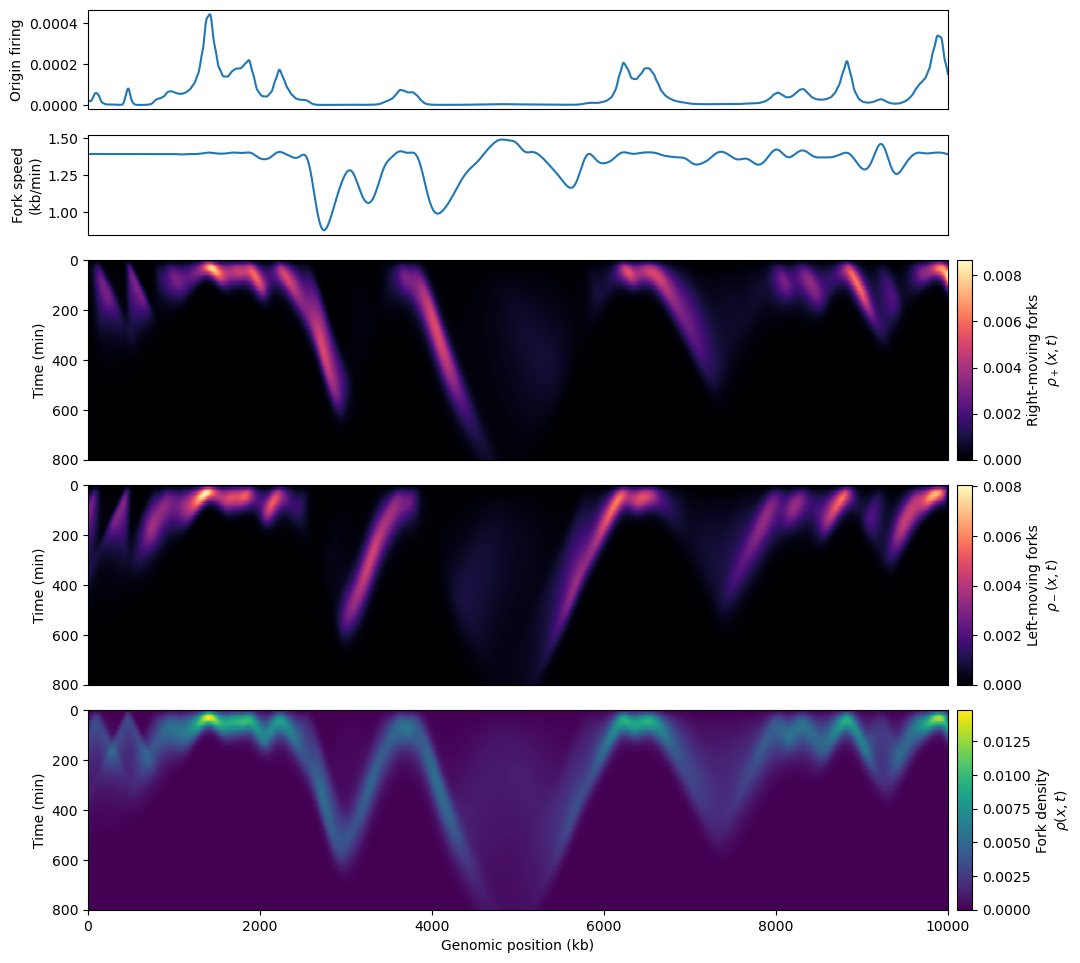

In [238]:
mplotf(
    [
        firing_rate_space_subset,
        fork_speed_space_subset,
        right_fork_density_xt,
        left_fork_density_xt,
        fork_density_xt,
    ],
    mlabels=[None, None, ["Right-moving forks\n"r"$\rho_+(x,t)$"], ["Left-moving forks\n"r"$\rho_-(x,t)$"], ["Fork density\n"r"$\rho(x,t)$"]],
    mx_array=positions_kb_subset,
    mtime_array=[None, None, fraction_time_grid, fraction_time_grid, fraction_time_grid],
    mxtitle="Genomic position (kb)",
    mytitle=["Origin firing", "Fork speed\n(kb/min)", "Time (min)", "Time (min)", "Time (min)"],
    mcmap=["viridis", "viridis", "magma", "magma", "viridis"],
    minvyQ=[False, False, True, True, True],
    mheight_ratios=[1, 1, 2, 2, 2],
    figsize=(10, 2.25),
    hspace=0.16,
)

**Directional-speed extension.** This example assumes $v_+(x)=v_-(x)$, but the same transport formulation can use distinct right- and left-moving speed fields. This would allow strand-specific obstacles or direction-dependent fork progression to be represented without changing the definitions of $\rho_+$ and $\rho_-$.

### 8.2 Note: fork directionality from fork densities

Fork directionality (RFD) can also be treated as a downstream mapping from the fork-density fields. It is a spatial profile, obtained by integrating the right- and left-moving fork densities over time before normalising their difference:

$$
\mathrm{RFD}(x)=\frac{\int \left[\rho_+(x,t)-\rho_-(x,t)\right]dt}
{\int \left[\rho_+(x,t)+\rho_-(x,t)\right]dt}.
$$

In `rmap`, this is the route `target="fork_directionality"` with source `fork_densities_xt` or with the explicit pair `right_fork_density_xt`, `left_fork_density_xt`. This keeps the RFD calculation tied to the same density fields used above.

In [152]:
rfd = rmap(
    source={"fork_densities_xt": fork_densities_xt},
    target="fork_directionality",
    assumptions={
        "time_grid": fraction_time_grid,
    },
)

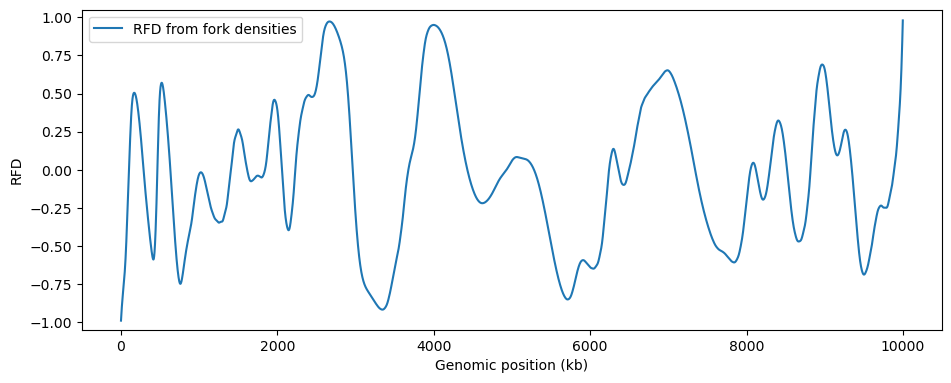

In [153]:
plotf(
    rfd,
    labels=["RFD from fork densities"],
    x_array=positions_kb_subset,
    xtitle="Genomic position (kb)",
    ytitle="RFD",
    ylims=(-1.05, 1.05),
)

## 9. Target: initiation-observation density

The initiation field $I(x,t)$ is a firing hazard per unit unreplicated DNA and time. It describes the potential to initiate, not the events that are ultimately realised: an origin cannot fire after its position has already been replicated passively. The observable initiation process must therefore be conditioned on the unreplicated fraction $1-f(x,t)$.

This distinction connects the model parameter $I$ to experimental origin usage. It also explains why increasing potential initiation does not necessarily produce a proportional increase in observed initiation events.

### 9.1 Initiation-observation density and $\phi_i(x,t)$

For a replication programme with initiation rate $I(x,t)$ and replicated fraction $f(x,t)$, an initiation can only be observed while the locus is still unreplicated. The paper therefore defines the probability density of observing an initiation event as

$$
\phi_i(x,t)=\frac{I(x,t)[1-f(x,t)]}{N_i},
$$

with

$$
N_i=\int_0^{\infty}\!\int_0^L I(x,t)[1-f(x,t)]\,dx\,dt.
$$

Here $N_i$ is the average number of initiations per replication cycle. DNAscape evaluates the numerator directly and normalizes it to obtain $\phi_i(x,t)$, which integrates to one over space and time.

In [154]:
initiation_event_density_xt = rmap(
    source={
        "firing_rate": firing_rate_space_subset,
        "replicated_fraction_xt": replicated_fraction_xt,
    },
    target="initiation_pdf_xt",
    assumptions={
        "time_grid": fraction_time_grid,
        "resolution_t": fraction_resolution_t,
        "x_array": positions_kb_subset,
    },
)

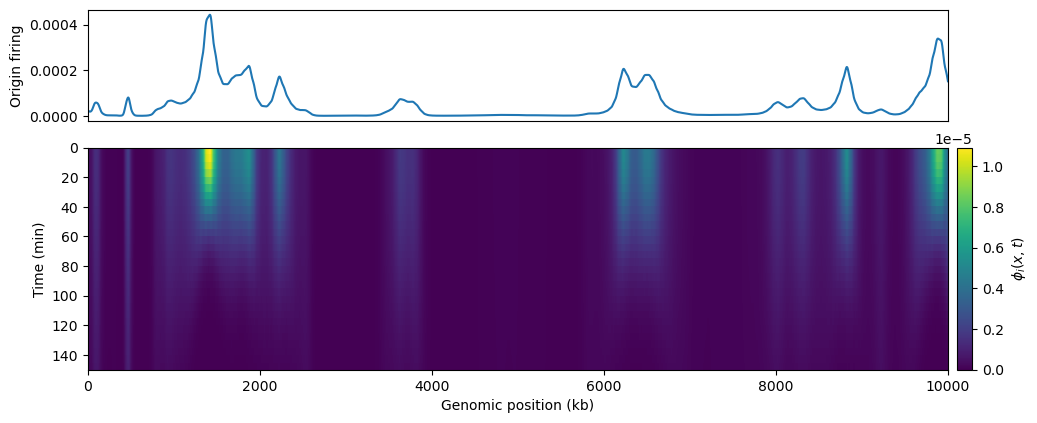

In [161]:
mplotf(
    [
        firing_rate_space_subset,
        initiation_event_density_xt,
    ],
    mlabels=[
        None,
        [r"$\phi_i(x,t)$"],
    ],
    mx_array=positions_kb_subset,
    mtime_array=[None, fraction_time_grid],
    mxtitle=["", "Genomic position (kb)"],
    mytitle=["Origin firing", "Time (min)"],
    mylims=[None, (0, 150)],
    minvyQ=[False, True],
    mheight_ratios=[1, 2],
    figsize=(10, 2.25),
    hspace=0.16,
)

### 9.2 Cumulative initiation profile

Integrating $\phi_i(x,t)$ over time gives a spatial probability density for observed initiations,

$$
\phi_i(x)=\int_0^{\infty}\phi_i(x,t)\,dt,
$$

with $\int_0^L\phi_i(x)\,dx=1$. This is the most natural object to compare with origin-mapping assays after accounting for passive replication.

In [156]:
cumulative_initiation_ix_vx = rmap(
    source={"initiation_pdf_xt": initiation_event_density_xt},
    target="initiation_pdf",
    assumptions={
        "time_grid": fraction_time_grid,
        "resolution_t": fraction_resolution_t,
    },
)

expected_initiation_count_ix_vx = np.trapezoid(
    rmap(
        source={
            "firing_rate": firing_rate_space_subset,
            "replicated_fraction_xt": replicated_fraction_xt,
        },
        target="initiation_events",
        assumptions={
            "time_grid": fraction_time_grid,
            "resolution_t": fraction_resolution_t,
        },
    ),
    x=positions_kb_subset,
)
phi_i_integral_ix_vx = np.trapezoid(
    cumulative_initiation_ix_vx,
    x=positions_kb_subset,
)
print(f"N_i in this interval: {expected_initiation_count_ix_vx:.2f}")
print(f"Integral of phi_i(x): {phi_i_integral_ix_vx:.3f}")

N_i in this interval: 40.55
Integral of phi_i(x): 1.000


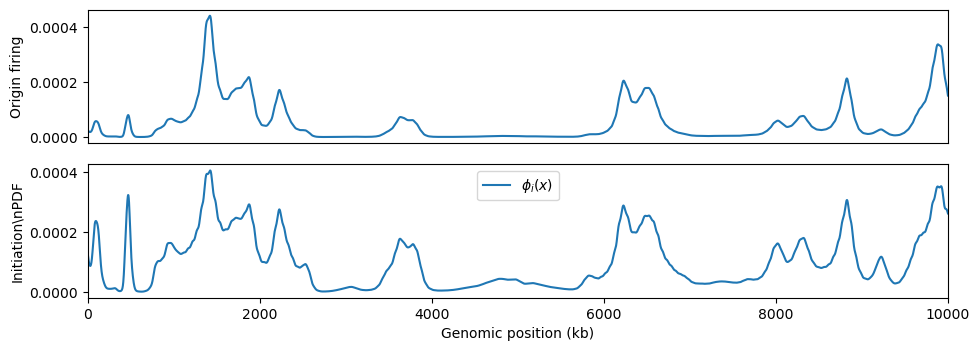

In [157]:
mplotf(
    [
        firing_rate_space_subset,
        cumulative_initiation_ix_vx,
    ],
    mlabels=[
        None,
        [r"$\phi_i(x)$"],
    ],
    mx_array=positions_kb_subset,
    mxtitle=["", "Genomic position (kb)"],
    mytitle=["Origin firing", "Initiation\\nPDF"],
    minvyQ=[False, False],
    mheight_ratios=[1, 1],
    figsize=(10, 1.8),
    hspace=0.16,
)

### 9.3 Origin and initiation-zone efficiency

For user-defined origin or initiation-zone windows $\Omega$, DNAscape can integrate either the unnormalized initiation-observation density or its normalized counterpart. In probability form,

$$
P_\Omega=\int_0^{\infty}\!\int_\Omega \phi_i(x,t)\,dx\,dt,
$$

and the corresponding expected number of observed initiations is

$$
E_\Omega=\int_0^{\infty}\!\int_\Omega I(x,t)[1-f(x,t)]\,dx\,dt=N_iP_\Omega.
$$

This makes it possible to report relative initiation probabilities, expected event counts, or regional efficiencies using the same windows.

In [158]:
initiation_zone_regions = {
    "upstream zone": (1_000, 2_000),
    "slow-speed zone": (4_000, 8_000),
    "downstream zone": (8_000, 9_500),
}

initiation_zone_efficiency = rmap(
    source={"initiation_pdf": cumulative_initiation_ix_vx},
    target="origin_efficiency",
    assumptions={
        "regions": initiation_zone_regions,
        "x_array": positions_kb_subset,
    },
)

zone_probabilities = initiation_zone_efficiency["expected_events"]
initiation_zone_efficiency_table = pd.DataFrame({
    "region": initiation_zone_efficiency["names"],
    "start_kb": initiation_zone_efficiency["regions"][:, 0],
    "end_kb": initiation_zone_efficiency["regions"][:, 1],
    "event_probability": zone_probabilities,
    "expected_events": zone_probabilities * expected_initiation_count_ix_vx,
})
initiation_zone_efficiency_table

,region,start_kb,end_kb,event_probability,expected_events
0,upstream zone,1000.0,2000.0,0.230095,9.330585
1,slow-speed zone,4000.0,8000.0,0.253945,10.297717
2,downstream zone,8000.0,9500.0,0.171073,6.937191


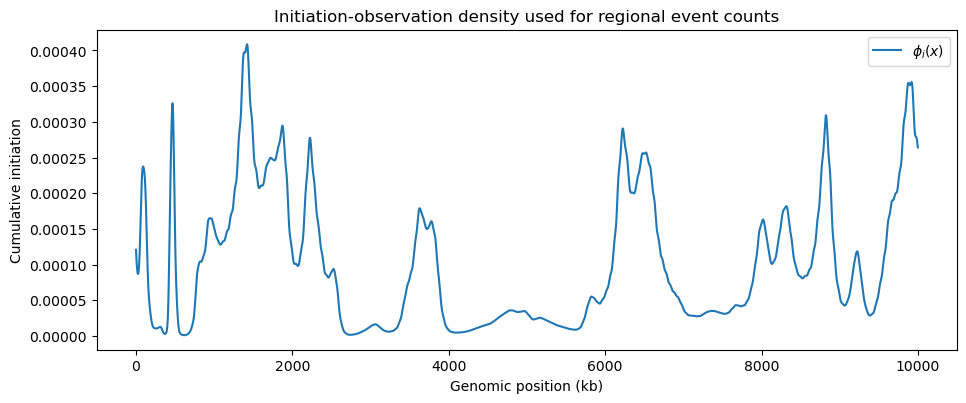

In [67]:
plotf(
    cumulative_initiation_ix_vx,
    labels=[r"$\phi_i(x)$"],
    x_array=positions_kb_subset,
    xtitle="Genomic position (kb)",
    ytitle="Cumulative initiation",
    title="Initiation-observation density used for regional event counts",
)

## 10. Target: fork termination

Replication terminates when oppositely moving forks meet. Because termination depends jointly on initiation, fork transport and the remaining unreplicated DNA, its distribution cannot be inferred from origin positions alone. The directional fork-density fields make it possible to map termination directly in space and time.

### 10.1 Coalescence-observation density and $\phi_c(x,t)$

Fork coalescence is the sink term of the directional fork-density equations. With right- and left-moving fork densities $\rho_+$ and $\rho_-$, and directional speeds $v_+$ and $v_-$, the paper defines

$$
\phi_c(x,t)=
\frac{[v_-(x,t)+v_+(x,t)]\rho_-(x,t)\rho_+(x,t)}
{N_c[1-f(x,t)]},
$$

where

$$
N_c=\int_0^{\infty}\!\int_0^L
\frac{[v_-(x,t)+v_+(x,t)]\rho_-(x,t)\rho_+(x,t)}
{1-f(x,t)}\,dx\,dt.
$$

In the current example $v_+(x)=v_-(x)=v(x)$. The `fork_densities_xt` bundle contains the directional fork densities and the replicated fraction generated by the same transport calculation, so passing the bundle directly lets `rmap` use matched fields for the numerator and denominator. The result is stored as `coalescence_event_density_xt` and represents the normalized density $\phi_c(x,t)$.

In [159]:
coalescence_event_density_xt = rmap(
    source={
        "fork_densities_xt": fork_densities_xt,
        "fork_speed": fork_speed_space_subset,
    },
    target="coalescence_pdf_xt",
    assumptions={
        "time_grid": fraction_time_grid,
        "resolution_t": fraction_resolution_t,
        "x_array": positions_kb_subset,
    },
)

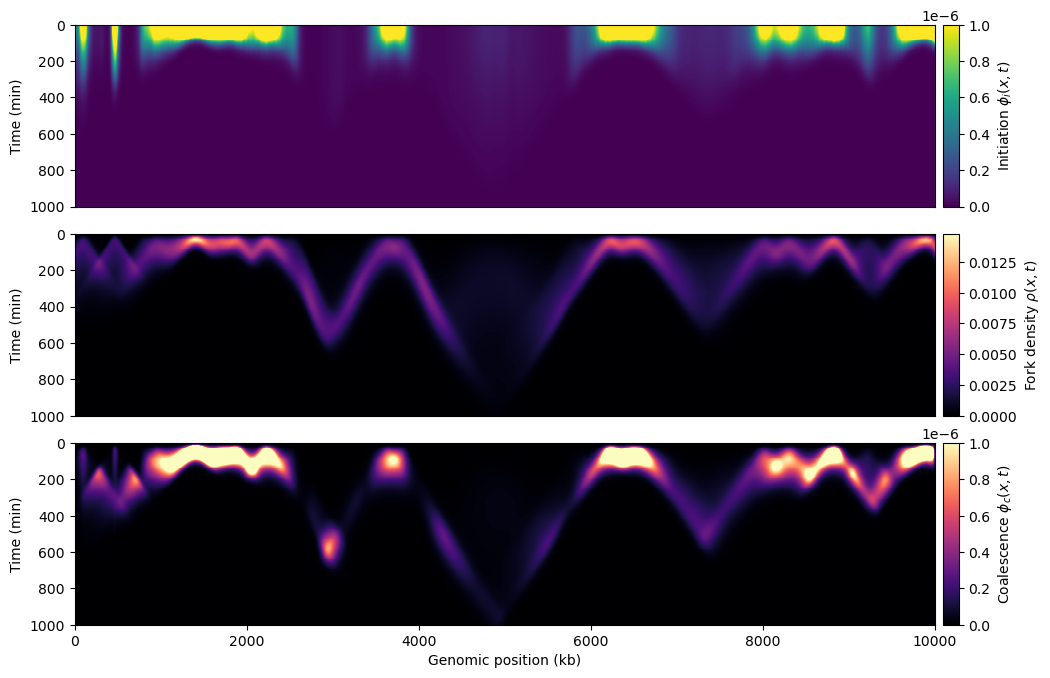

In [207]:
coalescence_event_density_max = np.nanpercentile(coalescence_event_density_xt, 99.9)

mplotf(
    [
        initiation_event_density_xt,
        fork_density_xt,
        coalescence_event_density_xt,
    ],
    mlabels=[
        [r"Initiation $\phi_i(x,t)$"],
        [r"Fork density $\rho(x,t)$"],
        [r"Coalescence $\phi_c(x,t)$"],
    ],
    mx_array=positions_kb_subset,
    mtime_array=fraction_time_grid,
    mxtitle="Genomic position (kb)",
    mytitle=["Time (min)", "Time (min)", "Time (min)"],
    mcmap=["viridis", "magma", "magma"],
    minvyQ=True,
    mzlims=[(0, 10**-6), None, (0, 10**-6)],
    mheight_ratios=[1, 1, 1],
    figsize=(10, 2.5),
)

### 10.2 Cumulative termination profile

As for initiation, the space-only termination profile is obtained by integrating the normalized coalescence-observation density over time,

$$
\phi_c(x)=\int_0^{\infty}\phi_c(x,t)\,dt,
$$

with $\int_0^L\phi_c(x)\,dx=1$. Comparing $\phi_c(x)$ with $\phi_i(x)$ shows how initiation, fork transport and passive replication reshape the locations where forks are expected to merge.

In [209]:
cumulative_coalescence_ix_vx = rmap(
    source={"coalescence_pdf_xt": coalescence_event_density_xt},
    target="coalescence_pdf",
    assumptions={
        "time_grid": fraction_time_grid,
        "resolution_t": fraction_resolution_t,
    },
)

expected_coalescence_count_ix_vx = np.trapezoid(
    rmap(
        source={
            "fork_densities_xt": fork_densities_xt,
            "fork_speed": fork_speed_space_subset,
        },
        target="coalescence_events",
        assumptions={
            "time_grid": fraction_time_grid,
            "resolution_t": fraction_resolution_t,
        },
    ),
    x=positions_kb_subset,
)
phi_c_integral_ix_vx = np.trapezoid(
    cumulative_coalescence_ix_vx,
    x=positions_kb_subset,
)
print(f"N_c in this interval: {expected_coalescence_count_ix_vx:.2f}")
print(f"Integral of phi_c(x): {phi_c_integral_ix_vx:.3f}")

N_c in this interval: 39.57
Integral of phi_c(x): 1.000


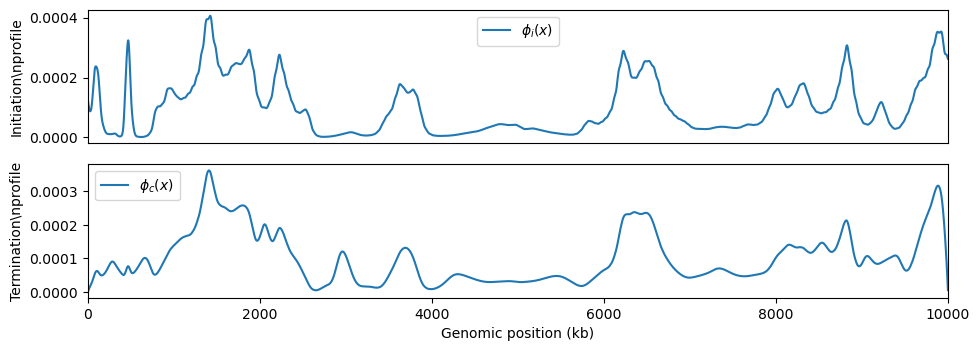

In [210]:
mplotf(
    [
        cumulative_initiation_ix_vx,
        cumulative_coalescence_ix_vx,
    ],
    mlabels=[
        [r"$\phi_i(x)$"],
        [r"$\phi_c(x)$"],
    ],
    mx_array=positions_kb_subset,
    mxtitle=["", "Genomic position (kb)"],
    mytitle=["Initiation\\nprofile", "Termination\\nprofile"],
    minvyQ=[False, False],
    mheight_ratios=[1, 1],
    figsize=(10, 1.8),
    hspace=0.16,
)

### 10.3 Initiation-termination balance

For a complete replication cycle, the average number of initiations and coalescences should be linked: every active replication domain begins with initiation and ends by coalescence or boundary termination. Numerically, we can compare

$$
N_i=\int_0^{\infty}\!\int_0^L I(x,t)[1-f(x,t)]\,dx\,dt
$$

with

$$
N_c=\int_0^{\infty}\!\int_0^L
\frac{[v_-(x,t)+v_+(x,t)]\rho_-(x,t)\rho_+(x,t)}
{1-f(x,t)}\,dx\,dt.
$$

This is a useful diagnostic for checking whether the discretized fields are mutually consistent.

In [208]:
initiation_termination_balance = pd.DataFrame({
    "quantity": [
        "expected initiation events",
        "expected coalescence events",
        "initiation minus coalescence",
    ],
    "value": [
        expected_initiation_count_ix_vx,
        expected_coalescence_count_ix_vx,
        expected_initiation_count_ix_vx - expected_coalescence_count_ix_vx,
    ],
})
initiation_termination_balance

,quantity,value
0,expected initiation events,40.550986
1,expected coalescence events,39.573886
2,initiation minus coalescence,0.977100


## 11. Target: replication-time distributions

At each position, $f(x,t)$ is a cumulative distribution for the time at which that locus becomes replicated. Replication timing should therefore be treated as a distribution rather than only as a single curve. This section will derive interpretable timing summaries directly from $f(x,t)$ and retain information about the breadth and asymmetry of local replication times.

### 11.1 Local replication-time quantiles

The replication-time quantile $t_q(x)$ is defined implicitly by

$$
f\!\left(x,t_q(x)\right)=q.
$$

In particular, $t_{50}(x)$ is the median replication time, while $t_{10}(x)$ and $t_{90}(x)$ delimit an early-to-late replication interval. The width

$$
\Delta t_{80}(x)=t_{90}(x)-t_{10}(x)
$$

measures how synchronously a locus replicates across the population. These summaries provide a direct bridge between the full $f(x,t)$ field and timing profiles comparable with Repli-seq-derived quantities.

### 11.2 Mean replication time and timing variability

The local replication-time density is

$$
p_T(x,t)=\frac{\partial f(x,t)}{\partial t}.
$$

Its mean can be calculated as

$$
\langle T(x)\rangle=\int_0^{\infty}t\,p_T(x,t)\,dt
=\int_0^{\infty}[1-f(x,t)]\,dt,
$$

with higher moments providing the local timing variance. Comparing the mean, median and quantile width will reveal skewed or broad replication-time distributions that are hidden by a single timing estimate.

### 11.3 Replication start and completion distributions

For an isolated region of length $L$ without incoming boundary forks, the expected cumulative initiation hazard before time $t$ is

$$
N_{\mathrm{expt}}(t)=\int_0^t\!\int_0^L I(x,\tau)\,dx\,d\tau,
$$

giving the probability that replication has started,

$$
P_s(t)=1-\exp[-N_{\mathrm{expt}}(t)],
\qquad w_s(t)=\frac{dP_s}{dt}.
$$

The completion probability $P_e(t)$ will be estimated from $f$ and the remaining fork densities, with the exact expression depending on periodic, linear or subregion boundary conditions. Its derivative $w_e(t)$ gives the distribution of completion times. Incoming forks must be included explicitly when the analysed interval is part of a larger chromosome.

## 12. Target: experimental observables

The kinetic fields are biological interpretations, whereas experimental assays observe transformed, sampled and often population-averaged versions of those fields. This section will define explicit observation models that convert DNAscape outputs into quantities appropriate for particular data types. Keeping this layer separate prevents assay-specific biases from being mistaken for initiation or fork-speed kinetics.

### 12.1 Population replication profiles

Time-course and fractionated Repli-seq measurements will be represented as temporal sampling operators applied to $f(x,t)$ or $\partial_t f(x,t)$. A generic assay bin $B_k$ can be written as

$$
R_k(x)=\int W_k(t)\,p_T(x,t)\,dt,
$$

where $W_k(t)$ represents the experimental time window, sorting distribution or labelling protocol. This formulation allows timing data to be compared with the model without assuming that an observed track is itself the underlying initiation rate.

### 12.2 Fork-direction and fork-density measurements

Fork-seq, OK-seq, DNA-fibre and related measurements can be connected to $\rho_+$, $\rho_-$, $D_\rho$ and $D_J$. Depending on the assay, the predicted observable may be an instantaneous field, a time-integrated density or a profile conditioned on molecules that are actively replicating. The mapping will therefore expose the relevant averaging and normalisation explicitly rather than treating every directionality track as equivalent.

### 12.3 Initiation-mapping measurements

SNS-seq, Ini-seq and related origin-mapping assays do not directly report the imposed initiation rate $I(x,t)$. They are closer to a time-integrated observation signal,

$$
\int_0^{\infty} I(x,t)[1-f(x,t)]\,dt,
$$

or to the normalized counterpart

$$
\phi_i(x)=\int_0^{\infty}\phi_i(x,t)\,dt,
$$

depending on whether the assay is interpreted as an absolute initiation-count signal or as a probability distribution over observed initiation sites. Additional assay-specific terms may account for fragment recovery, nascent-strand stability, sequence bias and normalisation. This distinction will allow DNAscape to test whether an observed origin signal is compatible with a kinetic initiation programme after passive replication is taken into account.

### 12.4 Single-molecule and asynchronous-population measurements

For SMARD-like experiments, molecules are sampled only after replication has started and before it has completed. The paper motivates time-integrated observables such as

$$
Y(x)=\frac{\int [f(x,t)-P_e(t)]\,dt}
{\int P_s(t)[1-P_e(t)]\,dt},
$$

and directional fork profiles

$$
V_\pm(x)=\frac{\int \rho_\pm(x,t)\,dt}
{\int P_s(t)[1-P_e(t)]\,dt}.
$$

These mappings incorporate the experimental selection of actively replicating molecules and provide a route for fitting initiation, fork speed and boundary-fork influx jointly from multiple correlated measurements.

### 12.5 Comparative and perturbation mappings

Once the same observables have been calculated for two conditions, DNAscape can map changes in the complete replication programme. For any field $g$, a signed or absolute contrast can be defined as

$$
\Delta g(x,t)=g_B(x,t)-g_A(x,t),
\qquad
|\Delta g(x,t)|.
$$

Applying this consistently to replicated fraction, fork density, initiation-observation density, termination and timing distributions will make it possible to distinguish whether a perturbation primarily changes origin activity, fork progression, passive replication or completion dynamics. These comparisons are particularly relevant for replication stress, fork-stalling hypotheses and therapeutic perturbations.

## Core mapping routes (dev only)

In [20]:
rmap.development()

,target,required data,data forms,required assumptions,optional assumptions,assumption forms,assumption values,method,status,description
0,replication_timing,"firing_rate, fork_speed",firing_rate: scalar/x; fork_speed: scalar/x,-,"resolution_x, neighbourhood_range, perQ, n_bins, genome_length, interval_kb",-,-,firing_and_speed_to_timing_deterministic,implemented,Deterministic mapping for I0 or I(x) with v0 or spatial effective v(x).
1,replication_timing,"firing_rate, fork_speed",firing_rate: scalar/x/t/xt; fork_speed: t/xt,-,"resolution_x, neighbourhood_range, perQ, n_bins, genome_length, interval_kb",-,-,firing_and_variable_speed_to_timing,needs method,Forward timing maps with time-only or space-time fork speed need dedicated methods.
2,firing_rate,"replication_timing, fork_speed",replication_timing: x; fork_speed: scalar,target_form,"resolution_x, neighbourhood_range, fit_step, maxiter, err_threshold, rate_bounds, verbose, print_every, perQ, n_bins",-,target_form: constant,timing_and_speed_to_constant_firing_rate,implemented,Scalar fit of I0 from timing and constant fork speed.
3,firing_rate,"replication_timing, fork_speed",replication_timing: x; fork_speed: scalar,-,"resolution_x, neighbourhood_range, fit_step, maxiter, sim_number, err_threshold, deviation_threshold, fit_step_x, maxiter_x, verbose, print_every, perQ, stall_rate, tau, target_form",-,target_form: space,timing_and_speed_to_firing_rate,implemented,Iterative fit of I(x) from timing and constant fork speed.
4,firing_rate,"replication_timing, fork_speed",replication_timing: x; fork_speed: x/t/xt,target_form,"resolution_x, resolution_t, neighbourhood_range, fit_step, maxiter, sim_number, err_threshold, rate_bounds, refine_seed, verbose, print_every, perQ, n_bins",-,target_form: constant,timing_and_variable_speed_to_firing_rate,implemented,Scalar effective fit of I0 from timing with variable fork speed.
5,firing_rate,"replication_timing, fork_speed",replication_timing: x; fork_speed: x/t/xt,-,"resolution_x, neighbourhood_range, fit_step, maxiter, sim_number, err_threshold, deviation_threshold, fit_step_x, maxiter_x, verbose, print_every, perQ, stall_rate, tau, target_form",-,target_form: space,timing_and_variable_speed_to_spatial_firing_rate,implemented,Space-dependent effective fit of I(x) from timing with variable fork speed.
6,fork_speed,"replication_timing, firing_rate",replication_timing: x; firing_rate: scalar/x,-,"resolution_x, neighbourhood_range, fit_step, maxiter, speed_bounds, initial_fork_speed, verbose, print_every, perQ, n_bins, target_form",-,target_form: constant,timing_and_firing_to_constant_fork_speed,implemented,Scalar fit of v0 from timing and firing rate.
7,fork_speed,"replication_timing, firing_rate",replication_timing: x; firing_rate: t/xt,target_form,"resolution_x, resolution_t, fit_step, maxiter, sim_number, speed_bounds, initial_fork_speed, refine_seed, verbose, print_every, perQ, n_bins, target_form",-,target_form: constant,timing_and_time_firing_to_constant_fork_speed,implemented,Scalar effective fit of v0 from timing and time-dependent firing rate.
8,fork_speed,"replication_timing, firing_rate",replication_timing: x; firing_rate: scalar/x,-,"resolution_x, neighbourhood_range, fit_step, maxiter, fit_step_x, maxiter_x, speed_bounds, initial_fork_speed, smoothw, verbose, print_every, perQ, n_bins, target_form",-,target_form: space,timing_and_firing_to_spatial_fork_speed,implemented,Spatial effective fit of v(x) from timing and firing rate.
9,fork_speed,"replication_timing, firing_rate",replication_timing: x; firing_rate: t/xt,-,"resolution_x, resolution_t, fit_step, maxiter, fit_step_x, maxiter_x, sim_number, speed_bounds, initial_fork_speed, smoothw, refine_seed, verbose, print_every, perQ, n_bins, target_form",-,target_form: space,timing_and_time_firing_to_spatial_fork_speed,implemented,Spatial effective fit of v(x) from timing and time-dependent firing rate.
